# Residential → POI weighted graph

**One edge means one retained minimum-cost walking route.** The graph excludes residence–residence and POI–POI connections. Detailed streets are retained underneath only to calculate routes.

We export two separate graphs: shortest-distance/time and lowest-friction. Each keeps one route per reachable pair, not multiple alternatives. The same street segment can be shared by several retained routes.

**Current inventory:** four provisional block-origin examples and 85 POI candidates. This is not an inventory of all houses or verified residential entrances. Review the candidates before making housing recommendations.


## Prototype graph available

The builder now exports `prototype_friction_activity_graph.graphml` alongside the original strict graph and a pessimistic sensitivity graph. The default full geographic viewer is in Notebook 19.

- **Prototype:** 328 reachable pairs from all four origins; partial-data costs explicitly estimated.
- **Original strict friction:** 79 pairs, from one origin.
- **Sensitivity:** 184 prototype routes change when missing factors are assumed high-burden.

In the geographic route preview farther down, set `objective = 'prototype_friction'`. The schematic diagram still compares the original strict graph to distance-only; it is not the prototype default.


## See the weighted graph

**The graph is shown below.** Orange nodes are provisional residential origins; blue nodes are destinations. Lines represent retained walking routes. The static overview shows a readable subset. In the interactive version, choose a route objective and origin, then hover over a line to see its weight.

Open `output/residential_poi_graph/weighted_graph.html` in your browser for the full-size interactive view. The geographic route map remains farther down this notebook.

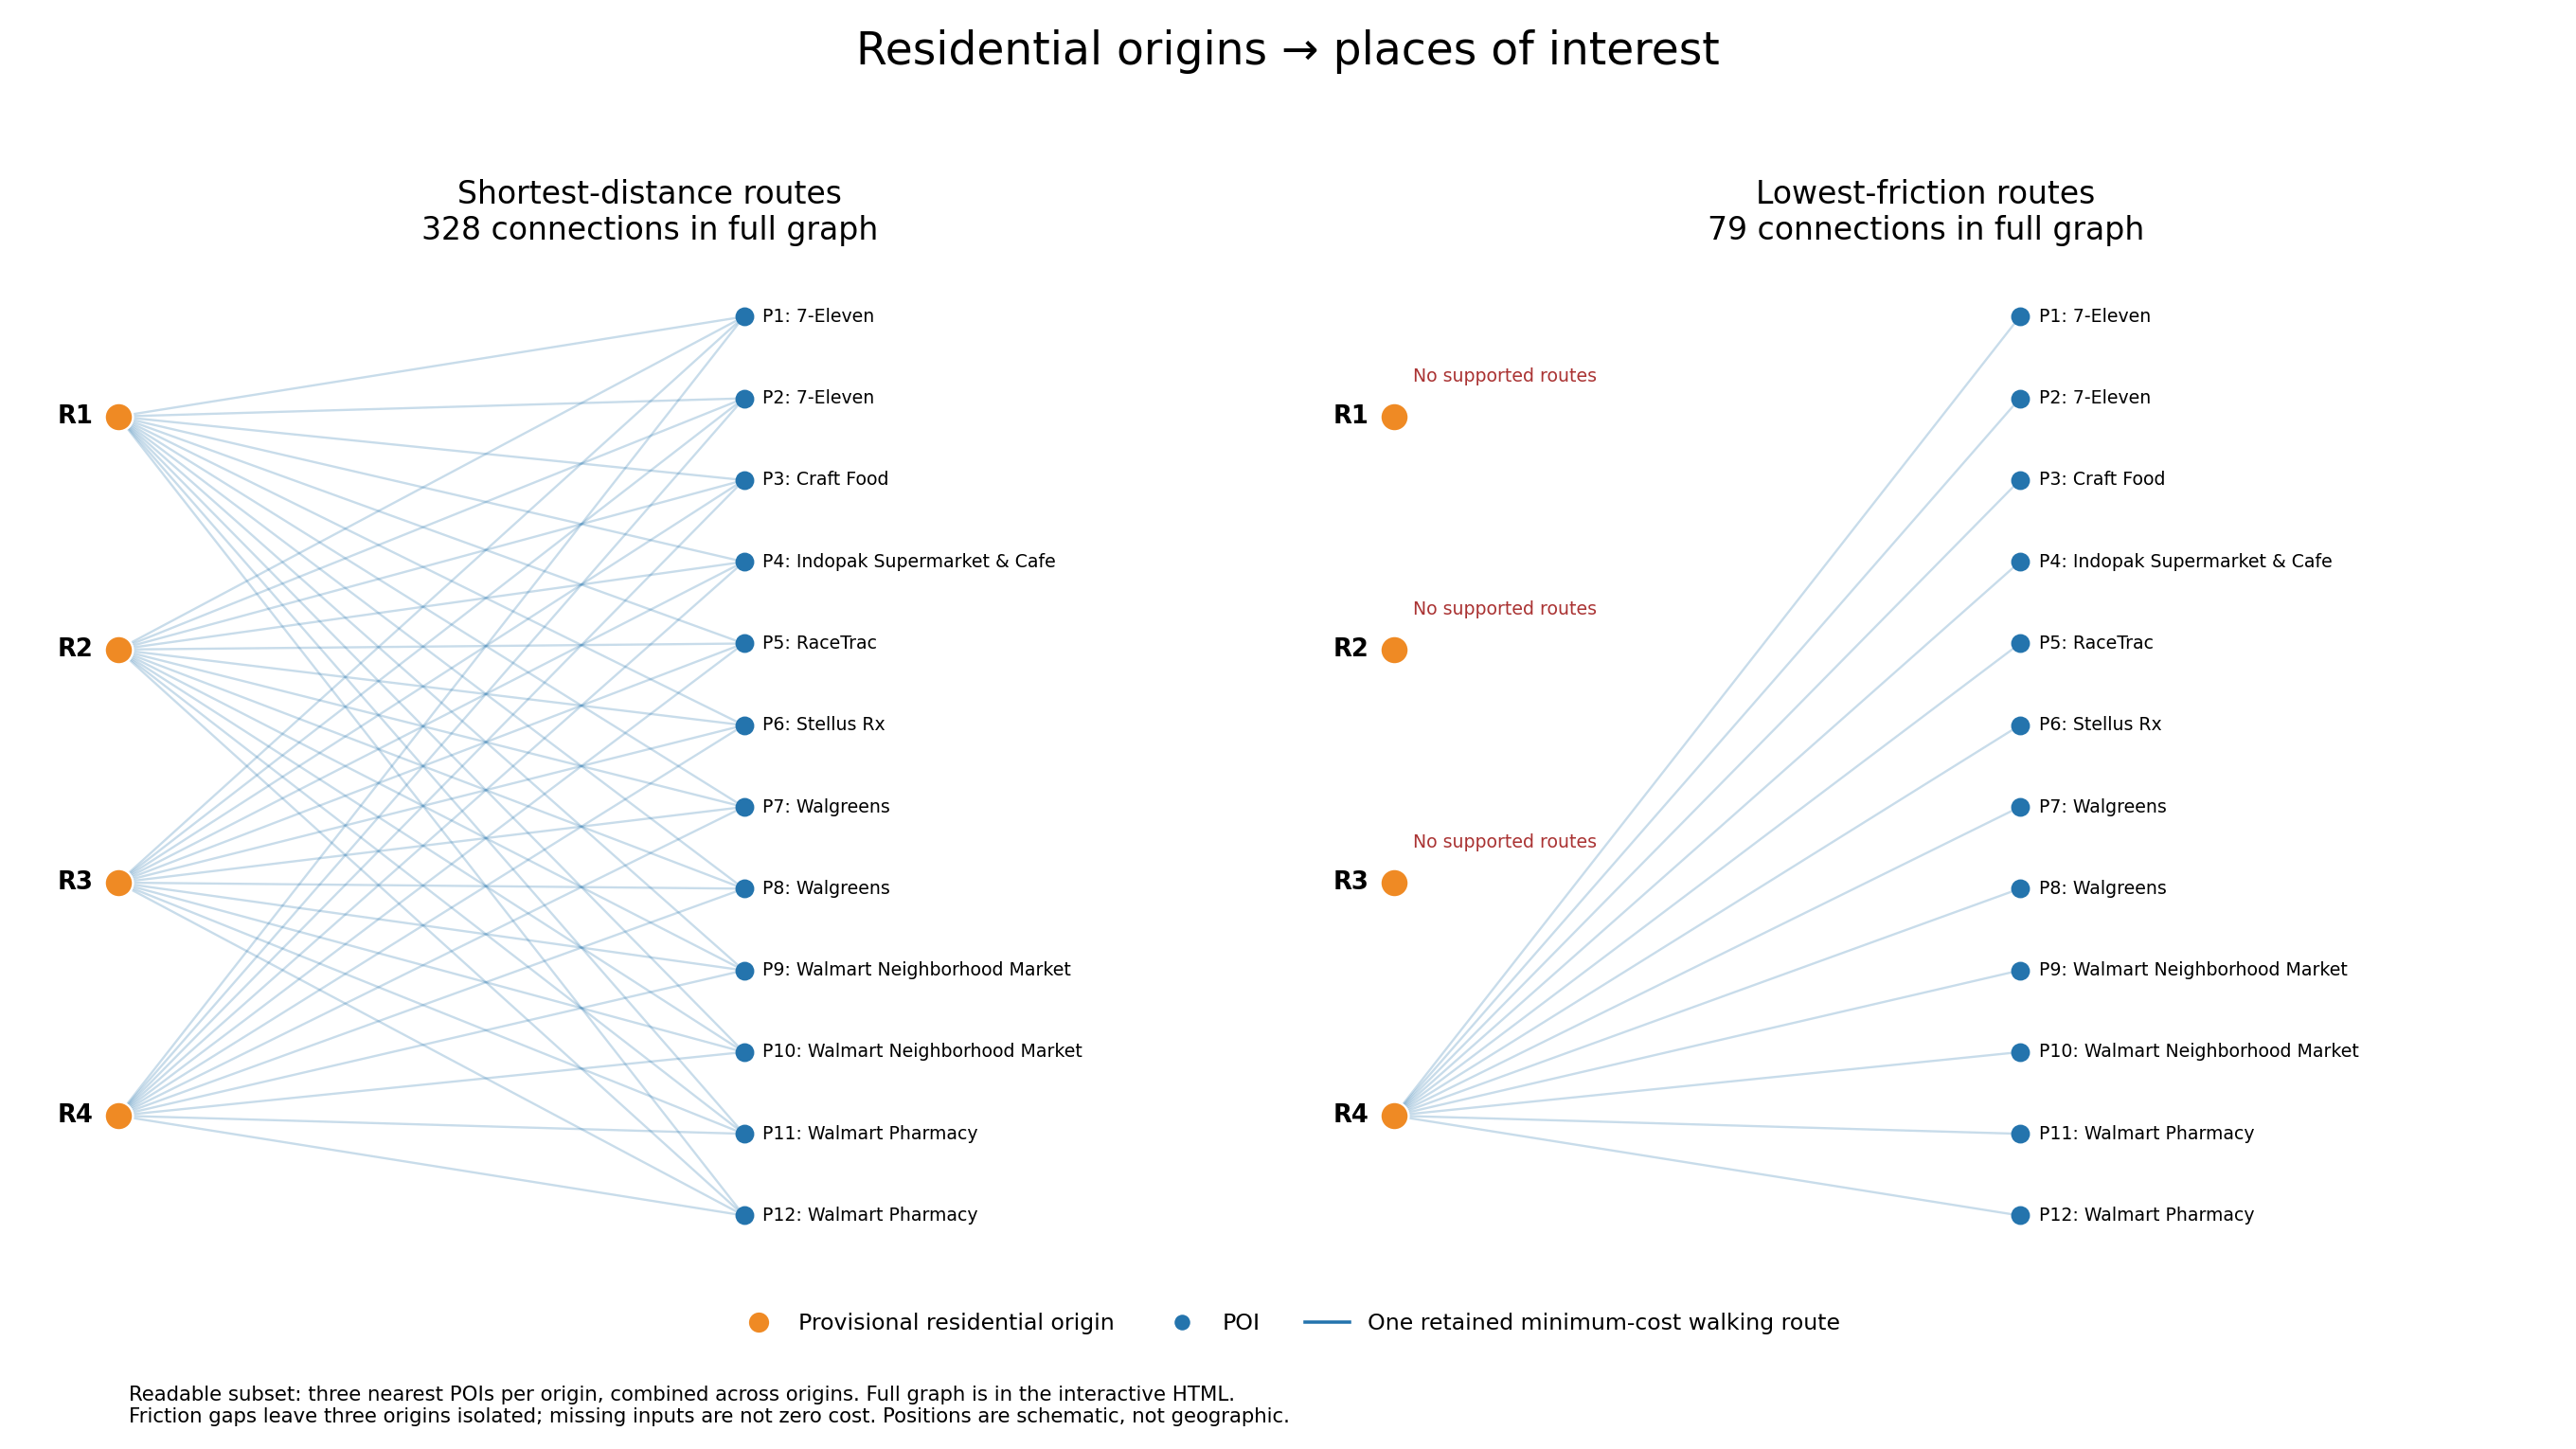

In [ ]:
from pathlib import Path
import sys, base64
from IPython.display import display, Image, HTML
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
from visualize_residential_poi_graph import run as draw_activity_graph
html_path, png_path = draw_activity_graph()
display(Image(filename=str(png_path)))
encoded = base64.b64encode(html_path.read_bytes()).decode()
display(HTML(f'<iframe src="data:text/html;base64,{encoded}" width="100%" height="850" style="border:0" title="Interactive residential to POI graph"></iframe>'))


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
from build_residential_poi_graph import run
report, costs = run()
display(pd.DataFrame(report['objectives']).T)


,activity_nodes,origin_to_poi_edges,unreachable_pairs,unique_selected_walking_edges,supported_substrate_edges
shortest_time,89,328,12,5554,93452
lowest_friction,89,79,261,2257,80110


## Read the weights

- `weight`: total route cost in seconds; friction costs are **equivalent** seconds.
- `distance_m`: physical walking-network length.
- `network_walk_minutes`: ordinary constant-speed walking time along that route.
- Missing required factors can make a friction route unavailable. Unknown routes are not zero-cost routes.
- Time-only and friction exports can have different supported edges. Use Notebook 17 for controlled same-support comparisons.
- We do not join houses to houses or send a route onward from a POI. An activity edge follows the actual walking network rather than a straight line between markers.


In [2]:
display(costs.head(12))
display(costs.groupby(['objective', 'status']).size().rename('pairs').to_frame())


,objective,origin,destination,origin_gap_m,destination_gap_m,access_verified,status,weight,distance_m,network_walk_minutes,cost_equivalent_minutes,segment_count
0,shortest_time,block_480850316283000,poi_1,18.028379,22.815949,False,provisional_network_route,2409.993650,2891.992380,40.166561,40.166561,42.0
1,shortest_time,block_480850316283000,poi_2,18.028379,42.342591,False,provisional_network_route,3460.841033,4153.009239,57.680684,57.680684,54.0
2,shortest_time,block_480850316283000,poi_3,18.028379,38.130298,False,provisional_network_route,4486.242008,5383.490409,74.770700,74.770700,102.0
3,shortest_time,block_480850316283000,poi_4,18.028379,19.909796,False,provisional_network_route,4524.506185,5429.407422,75.408436,75.408436,92.0
4,shortest_time,block_480850316283000,poi_5,18.028379,20.621767,False,provisional_network_route,320.510729,384.612875,5.341845,5.341845,10.0
5,shortest_time,block_480850316283000,poi_6,18.028379,53.251048,False,provisional_network_route,8629.652475,10355.582970,143.827541,143.827541,182.0
6,shortest_time,block_480850316283000,poi_7,18.028379,22.638552,False,provisional_network_route,3248.943120,3898.731744,54.149052,54.149052,65.0
7,shortest_time,block_480850316283000,poi_10,18.028379,12.673946,False,provisional_network_route,2760.208992,3312.250790,46.003483,46.003483,68.0
8,shortest_time,block_480850316283000,poi_11,18.028379,19.382353,False,provisional_network_route,4938.681379,5926.417655,82.311356,82.311356,115.0
9,shortest_time,block_480850316283000,poi_14,18.028379,32.382997,False,provisional_network_route,4202.110387,5042.532465,70.035173,70.035173,86.0


pairs
objective       status                                           
lowest_friction provisional_network_route                      79
                unreachable_on_objective_supported_network    261
shortest_time   provisional_network_route                     328
                unreachable_on_objective_supported_network     12

## View routes from one origin

Choose the objective and origin below. Toggle individual destinations in the map's layer control. To keep the display manageable, the preview shows the five nearest available destinations; the saved graph contains all reachable pairs.

This preview has no remote basemap dependency. ZIP boundaries and actual walking-route geometries supply context. It is not a validated navigation map.


In [ ]:
import geopandas as gpd
import folium
objective = 'prototype_friction'  # or 'shortest_time', 'lowest_friction', 'missing_high_burden_sensitivity'
nodes = gpd.read_file(ROOT / 'output/residential_poi_graph/activity_nodes.gpkg').to_crs(4326)
origin_id = nodes.loc[nodes.role.eq('origin'), 'location_id'].iloc[0]  # change to another listed origin
print(nodes.loc[nodes.role.eq('origin'), ['location_id', 'label']].to_string(index=False))
routes = gpd.read_file(ROOT / 'output/residential_poi_graph/origin_poi_routes.gpkg').to_crs(4326)
selected = routes[(routes.objective == objective) & (routes.origin == origin_id)].nsmallest(5, 'distance_m')
origin = nodes[nodes.location_id.eq(origin_id)].iloc[0]
m = folium.Map(location=[origin.geometry.y, origin.geometry.x], zoom_start=13, tiles=None)
bounds = gpd.read_file(ROOT / 'output/four_zip_walking_network/zip_boundaries.geojson').to_crs(4326)
folium.GeoJson(json.loads(bounds.to_json()), name='ZIP boundaries', style_function=lambda f: {'color':'#777','weight':1,'fillOpacity':0}).add_to(m)
colors = ['#006d2c','#2171b5','#d94801','#756bb1','#636363']
for color, (_, r) in zip(colors, selected.iterrows()):
    label = nodes.loc[nodes.location_id.eq(r.destination), 'label'].iloc[0]
    group = folium.FeatureGroup(name=str(label))
    folium.GeoJson(r.geometry.__geo_interface__, style_function=lambda f, color=color: {'color':color,'weight':4}, tooltip=f'{label} · {r.distance_m:.0f} m · {r.network_walk_minutes:.1f} network minutes').add_to(group)
    dest = nodes[nodes.location_id.eq(r.destination)].iloc[0]
    folium.CircleMarker([dest.geometry.y,dest.geometry.x], radius=5, color=color, tooltip=str(label)).add_to(group)
    group.add_to(m)
folium.Marker([origin.geometry.y, origin.geometry.x], tooltip='Provisional origin: '+str(origin.label)).add_to(m)
if not selected.empty:
    x1,y1,x2,y2 = selected.total_bounds
    m.fit_bounds([[y1,x1],[y2,x2]])
folium.LayerControl(collapsed=False).add_to(m)
m.save(str(ROOT / 'output/residential_poi_graph/selected_origin_preview.html'))
m


## Saved deliverables

Folder: `output/residential_poi_graph/`

- `lowest_friction_activity_graph.graphml`: residential-origin → POI weighted graph.
- `shortest_time_activity_graph.graphml`: shortest-distance/time baseline graph.
- `origin_poi_costs.csv`: reachable/unreachable pairs and costs.
- `origin_poi_routes.gpkg`: actual route lines for every retained pair.
- `route_segments.csv`: ordered detailed edge IDs behind each activity edge.
- `*_selected_network.gpkg`: union of used walking segments only, with shared segments deduplicated.
- `activity_nodes.gpkg`: provisional activity locations.
- `graph_method.json`: assumptions, inventory and checks.

To expand origins, review and extend the candidate input with legitimate residential access points, rerun the connection stage, then rerun this notebook. Do not infer that every address-containing block is residential. Do not change the underlying pedestrian graph by deleting residential streets: those streets are still necessary to reach services.
